# Air Quality Analysis – SI Project
**Practicals 1–8 | Simple student-style code**

Dataset: `Air_Quality_Analysis.csv`

## Practical 1: Data loading, inspection and cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/Air_Quality_Analysis.csv')
df.head()

,Date,City,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,AQI,AQI_Category
0,2025-01-01,Delhi,27.2,18.0,82.3,155.7,34.1,7.2,1.76,152.1,Moderate
1,2025-01-02,Chennai,28.4,30.7,40.1,82.1,38.0,5.5,0.70,91.6,Satisfactory
2,2025-01-03,Nagpur,27.5,44.7,39.9,87.3,28.0,1.0,0.76,66.0,Satisfactory
3,2025-01-04,Pune,29.9,49.1,49.8,70.0,42.2,7.5,0.71,97.1,Satisfactory
4,2025-01-05,Pune,37.8,51.5,82.0,164.8,29.3,16.4,1.26,150.9,Moderate


In [3]:
df.tail()

,Date,City,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,AQI,AQI_Category
595,2026-08-19,Chennai,22.0,63.3,122.4,221.1,40.1,10.6,1.72,184.7,Moderate
596,2026-08-20,Nagpur,22.4,70.4,72.5,131.8,23.6,21.6,0.78,139.8,Moderate
597,2026-08-21,Chennai,30.7,45.0,32.2,49.8,28.6,7.2,0.74,82.7,Satisfactory
598,2026-08-22,Nagpur,36.5,72.0,25.3,39.5,30.1,14.5,0.47,68.4,Satisfactory
599,2026-08-23,Nagpur,26.4,36.0,140.1,267.4,31.0,12.5,2.03,216.0,Poor


In [4]:
df.shape

(600, 11)

In [5]:
df.columns

Index(['Date', 'City', 'Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2',
       'SO2', 'CO', 'AQI', 'AQI_Category'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          600 non-null    object 
 1   City          600 non-null    object 
 2   Temperature   600 non-null    float64
 3   Humidity      600 non-null    float64
 4   PM2.5         600 non-null    float64
 5   PM10          600 non-null    float64
 6   NO2           600 non-null    float64
 7   SO2           600 non-null    float64
 8   CO            600 non-null    float64
 9   AQI           600 non-null    float64
 10  AQI_Category  600 non-null    object 
dtypes: float64(8), object(3)
memory usage: 51.7+ KB


In [7]:
df.isnull().sum()

,0
Date,0
City,0
Temperature,0
Humidity,0
PM2.5,0
PM10,0
NO2,0
SO2,0
CO,0
AQI,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df = df.drop_duplicates()
df = df.fillna(df.mean(numeric_only=True))
df.isnull().sum()

,0
Date,0
City,0
Temperature,0
Humidity,0
PM2.5,0
PM10,0
NO2,0
SO2,0
CO,0
AQI,0


In [10]:
df['City'].value_counts()

,count
City,
Delhi,109
Chennai,108
Mumbai,98
Pune,97
Bengaluru,95
Nagpur,93


## Practical 2: Descriptive statistics and visualization

In [11]:
df.describe()

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,AQI
count,600.000000,600.000000,600.00000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,28.771667,58.175667,77.18200,131.767500,36.838333,13.097500,1.105717,137.314333
std,6.062237,16.229501,54.11917,95.863572,12.952087,5.059553,0.380538,71.503312
min,12.000000,15.000000,5.00000,10.000000,3.000000,1.000000,0.100000,13.400000
25%,24.700000,47.850000,38.77500,64.275000,28.500000,9.500000,0.847500,87.125000
50%,29.100000,58.500000,66.95000,110.750000,37.100000,13.000000,1.100000,123.950000
75%,32.800000,68.500000,100.55000,170.925000,44.675000,16.025000,1.340000,169.150000
max,45.000000,98.000000,300.00000,500.000000,83.300000,32.900000,2.280000,420.000000


In [12]:
print('Mean AQI:', df['AQI'].mean())
print('Median AQI:', df['AQI'].median())
print('Mode AQI:', df['AQI'].mode()[0])

Mean AQI: 137.31433333333334
Median AQI: 123.94999999999999
Mode AQI: 77.2


In [13]:
print('Minimum AQI:', df['AQI'].min())
print('Maximum AQI:', df['AQI'].max())
print('Standard deviation:', df['AQI'].std())

Minimum AQI: 13.4
Maximum AQI: 420.0
Standard deviation: 71.50331228226038


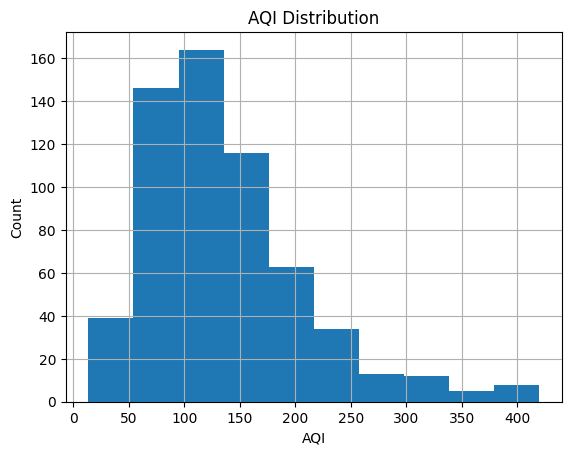

In [14]:
df['AQI'].hist()
plt.title('AQI Distribution')
plt.xlabel('AQI')
plt.ylabel('Count')
plt.show()

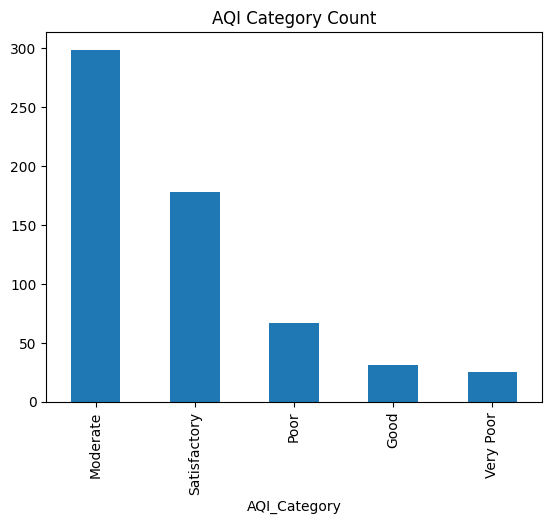

In [15]:
df['AQI_Category'].value_counts().plot(kind='bar')
plt.title('AQI Category Count')
plt.show()

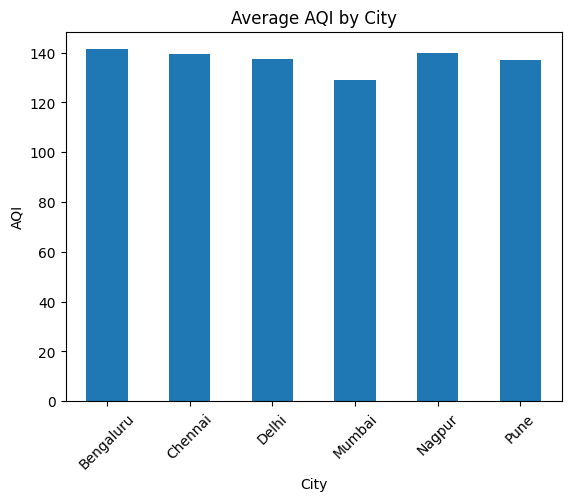

In [16]:
df.groupby('City')['AQI'].mean().plot(kind='bar')
plt.title('Average AQI by City')
plt.ylabel('AQI')
plt.xticks(rotation=45)
plt.show()

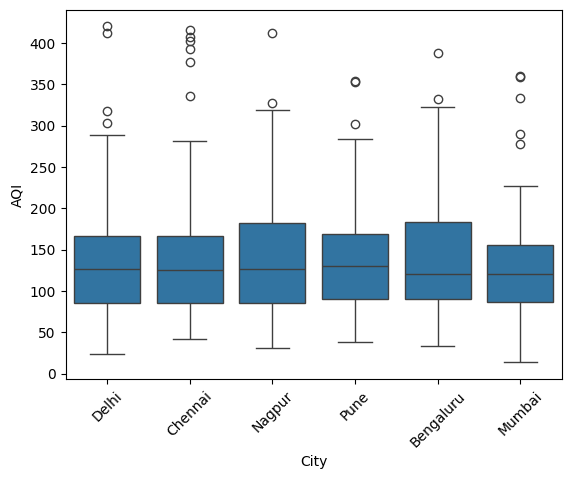

In [17]:
sns.boxplot(data=df, x='City', y='AQI')
plt.xticks(rotation=45)
plt.show()

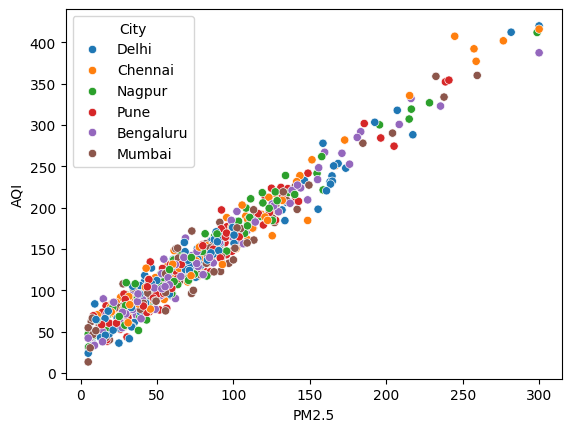

In [18]:
sns.scatterplot(data=df, x='PM2.5', y='AQI', hue='City')
plt.show()

## Practical 3: Sampling and sampling distribution

In [19]:
sample = df.sample(30, random_state=1)
sample.head()

,Date,City,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,AQI,AQI_Category
446,2026-03-23,Mumbai,30.7,64.6,39.1,70.8,28.0,13.3,1.11,77.2,Satisfactory
404,2026-02-09,Pune,34.7,51.7,92.0,173.8,54.2,13.8,0.88,174.6,Moderate
509,2026-05-25,Mumbai,35.4,55.1,204.1,348.9,43.6,8.7,1.20,290.3,Poor
455,2026-04-01,Nagpur,17.8,49.6,35.8,70.6,29.4,14.3,1.67,107.9,Moderate
201,2025-07-21,Bengaluru,33.0,53.6,41.3,74.1,22.1,12.9,1.13,75.8,Satisfactory


In [20]:
print('Sample mean:', sample['AQI'].mean())
print('Population mean:', df['AQI'].mean())

Sample mean: 148.08333333333334
Population mean: 137.31433333333334


In [21]:
sample_means = [df['AQI'].sample(30, replace=True).mean() for i in range(500)]
print('Mean of sample means:', np.mean(sample_means))

Mean of sample means: 138.2879


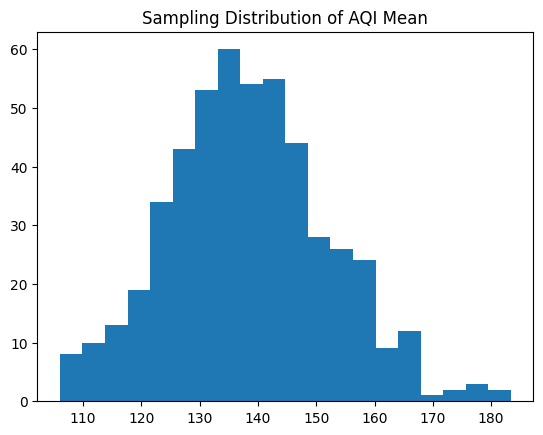

In [22]:
splt.hist(sample_means, bins=20)
plt.title('Sampling Distribution of AQI Mean')
plt.show()

## Practical 4: Central Limit Theorem

In [23]:
means30 = [df['AQI'].sample(30, replace=True).mean() for i in range(500)]
means50 = [df['AQI'].sample(50, replace=True).mean() for i in range(500)]

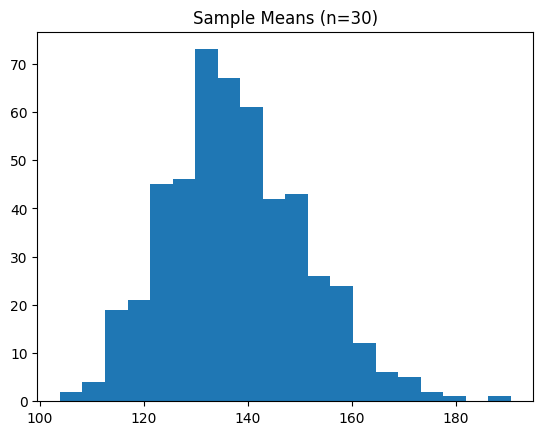

In [24]:
plt.hist(means30, bins=20)
plt.title('Sample Means (n=30)')
plt.show()

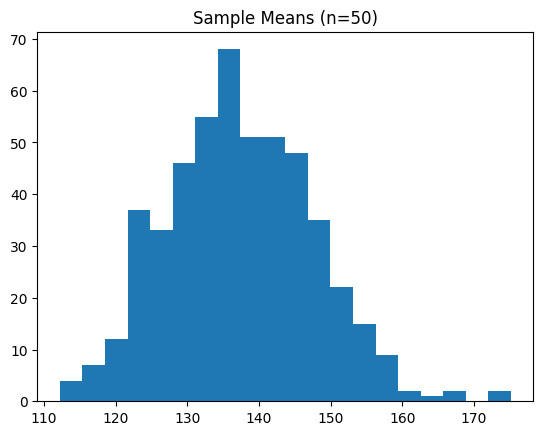

In [25]:
plt.hist(means50, bins=20)
plt.title('Sample Means (n=50)')
plt.show()

In [26]:
print('n=30:', np.mean(means30), np.std(means30))
print('n=50:', np.mean(means50), np.std(means50))

n=30: 137.90381333333332 13.341045715828361
n=50: 137.415032 10.190940190923309


## Practical 5: Confidence interval and one-sample t-test

In [27]:
from scipy.stats import t, ttest_1samp

In [28]:
x = df['AQI']
n = len(x)
mean = x.mean()
se = x.std() / np.sqrt(n)
print('Mean:', mean)
print('Standard error:', se)

Mean: 137.31433333333334
Standard error: 2.919110500173654


In [29]:
low = mean - t.ppf(0.975, n-1)*se
high = mean + t.ppf(0.975, n-1)*se
print('95% Confidence Interval:', low, high)

95% Confidence Interval: 131.58139808380756 143.04726858285912


In [30]:
print(ttest_1samp(df['AQI'], 100))

TtestResult(statistic=np.float64(12.782775208788282), pvalue=np.float64(2.9551005676257762e-33), df=np.int64(599))


## Practical 6: Hypothesis testing and relationship analysis

In [31]:
from scipy.stats import ttest_ind, norm, chi2_contingency, f_oneway, pearsonr, spearmanr

In [32]:
a = df[df['City']=='Delhi']['AQI']
b = df[df['City']=='Mumbai']['AQI']
print('t-test:', ttest_ind(a, b))

t-test: TtestResult(statistic=np.float64(0.8502002839872647), pvalue=np.float64(0.3962056270198224), df=np.float64(205.0))


In [33]:
z = (df['AQI'].mean()-100)/(df['AQI'].std()/np.sqrt(len(df)))
p = 2*(1-norm.cdf(abs(z)))
print('Z value:', z)
print('P value:', p)

Z value: 12.78277520878828
P value: 0.0


In [34]:
print('Correlation matrix')
print(df[['PM2.5','PM10','NO2','SO2','CO','AQI']].corr())

Correlation matrix
          PM2.5      PM10       NO2       SO2        CO       AQI
PM2.5  1.000000  0.964618  0.217133  0.210625  0.390116  0.977767
PM10   0.964618  1.000000  0.219170  0.201208  0.383265  0.961187
NO2    0.217133  0.219170  1.000000  0.045044  0.052720  0.335702
SO2    0.210625  0.201208  0.045044  1.000000  0.057505  0.238889
CO     0.390116  0.383265  0.052720  0.057505  1.000000  0.434051
AQI    0.977767  0.961187  0.335702  0.238889  0.434051  1.000000


In [35]:
print('Covariance matrix')
print(df[['PM2.5','PM10','NO2','SO2','CO','AQI']].cov())

Covariance matrix
             PM2.5         PM10         NO2        SO2         CO          AQI
PM2.5  2928.884517  5004.495307  152.200908  57.673127   8.034197  3783.663965
PM10   5004.495307  9189.824401  272.128777  97.591438  13.981415  6588.517061
NO2     152.200908   272.128777  167.756558   2.951832   0.259846   310.899466
SO2      57.673127    97.591438    2.951832  25.599076   0.110717    86.423992
CO        8.034197    13.981415    0.259846   0.110717   0.144809    11.810402
AQI    3783.663965  6588.517061  310.899466  86.423992  11.810402  5112.723667


In [36]:
print('Pearson:', pearsonr(df['PM2.5'], df['AQI']))
print('Spearman:', spearmanr(df['PM2.5'], df['AQI']))

Pearson: PearsonRResult(statistic=np.float64(0.9777667722386203), pvalue=np.float64(0.0))
Spearman: SignificanceResult(statistic=np.float64(0.96355056870037), pvalue=np.float64(0.0))


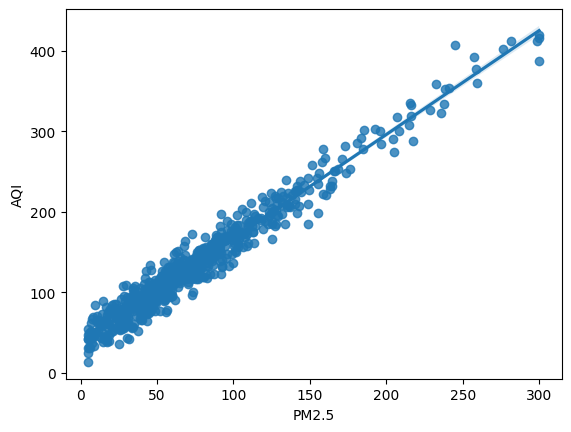

In [37]:
sns.regplot(data=df, x='PM2.5', y='AQI')
plt.show()

In [38]:
tab = pd.crosstab(df['City'], df['AQI_Category'])
print(tab)
print('Chi-square:', chi2_contingency(tab))

AQI_Category  Good  Moderate  Poor  Satisfactory  Very Poor
City                                                       
Bengaluru        5        43    15            28          4
Chennai          3        53     9            37          6
Delhi            9        54    13            29          4
Mumbai           6        52     7            30          3
Nagpur           4        47    11            26          5
Pune             4        50    12            28          3
Chi-square: Chi2ContingencyResult(statistic=np.float64(11.342645566466269), pvalue=np.float64(0.9368480579452109), dof=20, expected_freq=array([[ 4.90833333, 47.34166667, 10.60833333, 28.18333333,  3.95833333],
       [ 5.58      , 53.82      , 12.06      , 32.04      ,  4.5       ],
       [ 5.63166667, 54.31833333, 12.17166667, 32.33666667,  4.54166667],
       [ 5.06333333, 48.83666667, 10.94333333, 29.07333333,  4.08333333],
       [ 4.805     , 46.345     , 10.385     , 27.59      ,  3.875     ],
       [ 5.01

In [39]:
a = df[df['City']=='Delhi']['AQI']
b = df[df['City']=='Mumbai']['AQI']
c = df[df['City']=='Pune']['AQI']
print('ANOVA:', f_oneway(a, b, c))

ANOVA: F_onewayResult(statistic=np.float64(0.47768287286944633), pvalue=np.float64(0.6206882121475368))


## Practical 7: Regression analysis

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [41]:
X = df[['PM2.5','PM10','NO2','SO2','CO','Temperature','Humidity']]
y = df['AQI']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [42]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred = lr.predict(X_test)
print('MAE:', mean_absolute_error(y_test, pred))
print('MSE:', mean_squared_error(y_test, pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, pred)))
print('R2:', r2_score(y_test, pred))

MAE: 7.425327723856284
MSE: 86.45015735655855
RMSE: 9.297857675645425
R2: 0.9862145370926164


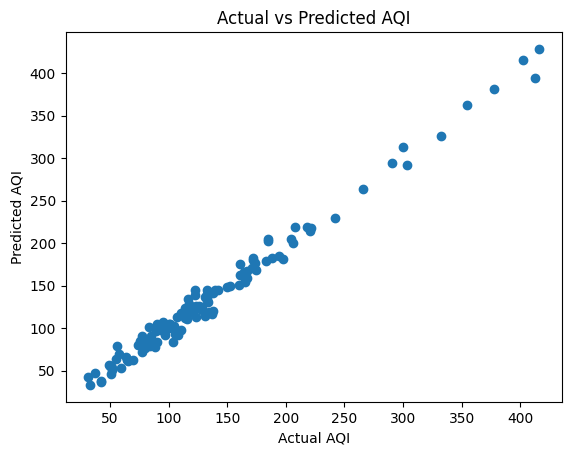

In [43]:
plt.scatter(y_test, pred)
plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title('Actual vs Predicted AQI')
plt.show()

In [44]:
rf = RandomForestRegressor(random_state=1)
rf.fit(X_train, y_train)
pred2 = rf.predict(X_test)
print('Random Forest R2:', r2_score(y_test, pred2))

Random Forest R2: 0.9764316134178403


In [45]:
pd.DataFrame({'Actual': y_test.values, 'Linear': pred, 'Random Forest': pred2}).head()

,Actual,Linear,Random Forest
0,77.2,86.304575,86.296
1,174.6,168.399323,173.845
2,290.3,294.905279,293.364
3,107.9,91.426360,87.291
4,75.8,84.723600,83.586


## Practical 8: Classification

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [47]:
X = df[['PM2.5','PM10','NO2','SO2','CO','Temperature','Humidity']]
y = df['AQI_Category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

In [48]:
clf = RandomForestClassifier(random_state=1)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

Accuracy: 0.85
              precision    recall  f1-score   support

        Good       0.75      0.50      0.60         6
    Moderate       0.90      0.90      0.90        60
        Poor       0.83      0.77      0.80        13
Satisfactory       0.79      0.86      0.83        36
   Very Poor       0.80      0.80      0.80         5

    accuracy                           0.85       120
   macro avg       0.82      0.77      0.79       120
weighted avg       0.85      0.85      0.85       120



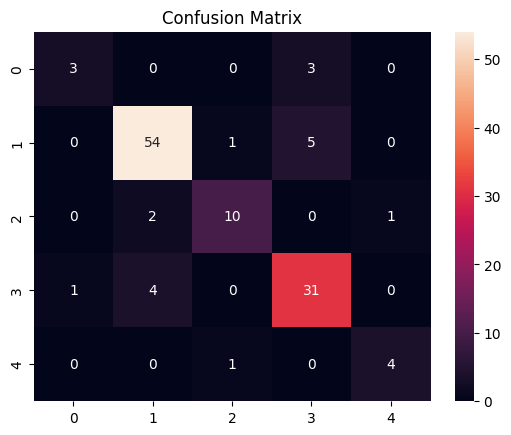

In [49]:
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.show()

In [50]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
pred2 = lr.predict(X_test)
print('Logistic Regression Accuracy:', accuracy_score(y_test, pred2))

Logistic Regression Accuracy: 0.8416666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Enhanced Gradio UI – Air Quality Dashboard
Run the cells above first, then run this cell to open the dashboard.

In [51]:
!pip -q install gradio

In [53]:
import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- Settings ----------
FEATURES   = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Temperature', 'Humidity']
POLLUTANTS = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO']

# colour + health advice for each AQI category (matched by keyword, so it works with any category names)
def category_info(category):
    c = str(category).lower()
    if 'severe' in c or 'hazard' in c:
        return '#7e0023', 'Health emergency. Avoid all outdoor activity and use an air purifier indoors.'
    if 'very poor' in c or 'very unhealthy' in c:
        return '#8f3f97', 'Everyone may feel health effects. Stay indoors and wear an N95 mask if you go out.'
    if 'poor' in c or 'unhealthy' in c:
        return '#ff0000', 'Breathing discomfort is likely. Limit outdoor exercise, especially for children and elderly people.'
    if 'moderate' in c:
        return '#ff9933', 'Acceptable for most people, but sensitive groups (asthma, heart patients) should take care.'
    if 'satisfactory' in c:
        return '#a3c853', 'Minor discomfort possible for very sensitive people. Normal activity is fine.'
    if 'good' in c:
        return '#009865', 'Air quality is good. Enjoy outdoor activities!'
    return '#607d8b', 'No advice available for this category.'

dataset_mean = df[POLLUTANTS].mean()

# ---------- Tab 1: Prediction ----------
def predict_aqi(pm25, pm10, no2, so2, co, temp, humidity):
    values = [pm25, pm10, no2, so2, co, temp, humidity]
    if any(v is None for v in values):
        return None, '<p style="color:red">⚠️ Please fill in all the fields.</p>', None

    x = pd.DataFrame([values], columns=FEATURES)

    # category (classification model) + probabilities
    category = clf.predict(x)[0]
    probs = {str(c): float(p) for c, p in zip(clf.classes_, clf.predict_proba(x)[0])}

    # numeric AQI estimate (Random Forest regression model from Practical 7)
    aqi_value = float(rf.predict(x)[0])

    colour, advice = category_info(category)
    card = f'''
    <div style="background:{colour}; color:white; padding:18px; border-radius:12px;">
        <div style="font-size:14px; opacity:0.9;">Predicted category</div>
        <div style="font-size:30px; font-weight:bold;">{category}</div>
        <div style="font-size:16px; margin-top:4px;">Estimated AQI: <b>{aqi_value:.0f}</b></div>
        <div style="margin-top:10px; font-size:14px;">🩺 {advice}</div>
    </div>'''

    # chart: your readings as % of the dataset average
    fig, ax = plt.subplots(figsize=(6, 3.5))
    percent = [v / dataset_mean[p] * 100 for v, p in zip(values[:5], POLLUTANTS)]
    ax.bar(POLLUTANTS, percent, color=colour)
    ax.axhline(100, color='black', linestyle='--', linewidth=1)
    ax.set_ylabel('% of dataset average')
    ax.set_title('Your readings vs dataset average (dashed line = 100%)')
    plt.tight_layout()
    plt.close(fig)

    return probs, card, fig

# ---------- Tab 2: Data explorer ----------
cities = ['All Cities'] + sorted(df['City'].dropna().unique().tolist())

def explore_city(city):
    data = df if city == 'All Cities' else df[df['City'] == city]

    summary = f'''### 📍 {city}
| Statistic | Value |
|---|---|
| Records | {len(data)} |
| Average AQI | {data['AQI'].mean():.1f} |
| Median AQI | {data['AQI'].median():.1f} |
| Minimum AQI | {data['AQI'].min():.0f} |
| Maximum AQI | {data['AQI'].max():.0f} |
| Most common category | {data['AQI_Category'].mode()[0]} |
'''
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].hist(data['AQI'], bins=20, color='steelblue', edgecolor='white')
    axes[0].set_title('AQI distribution')
    axes[0].set_xlabel('AQI')

    data['AQI_Category'].value_counts().plot(kind='bar', ax=axes[1], color='seagreen')
    axes[1].set_title('AQI categories')
    axes[1].tick_params(axis='x', rotation=45)

    data[POLLUTANTS].mean().plot(kind='bar', ax=axes[2], color='indianred')
    axes[2].set_title('Average pollutant levels')
    axes[2].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.close(fig)
    return summary, fig

def compare_cities():
    fig, ax = plt.subplots(figsize=(8, 4))
    avg = df.groupby('City')['AQI'].mean().sort_values(ascending=False)
    avg.plot(kind='bar', ax=ax, color='darkorange')
    ax.set_ylabel('Average AQI')
    ax.set_title('Average AQI by city (highest to lowest)')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.close(fig)
    return fig

# ---------- Tab 3: Model insights ----------
def model_insights():
    acc = accuracy_score(y_test, clf.predict(X_test))
    info = f'''### 🤖 Random Forest Classifier
- **Test accuracy:** {acc*100:.2f}%
- **Features used:** {', '.join(FEATURES)}
- **Categories predicted:** {', '.join(map(str, clf.classes_))}
'''
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    imp = pd.Series(clf.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind='barh', ax=axes[0], color='teal')
    axes[0].set_title('Feature importance')

    cm = confusion_matrix(y_test, clf.predict(X_test), labels=clf.classes_)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
                xticklabels=clf.classes_, yticklabels=clf.classes_)
    axes[1].set_title('Confusion matrix')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Actual')

    plt.tight_layout()
    plt.close(fig)
    return info, fig

# ---------- Build the dashboard ----------
with gr.Blocks(theme=gr.themes.Soft(), title='Air Quality Dashboard') as demo:
    gr.Markdown('''
    # 🌿 Air Quality Analysis Dashboard
    Predict air quality, explore the dataset and see how the model works.
    **Note:** The model is trained on the project dataset and is not a live monitoring service.
    ''')

    with gr.Tabs():

        # ----- Tab 1 -----
        with gr.Tab('🔮 Predict'):
            with gr.Row():
                with gr.Column():
                    gr.Markdown('### 🌫️ Pollution values')
                    pm25 = gr.Number(label='PM2.5 (µg/m³)', value=35, minimum=0)
                    pm10 = gr.Number(label='PM10 (µg/m³)', value=60, minimum=0)
                    no2  = gr.Number(label='NO2 (µg/m³)', value=20, minimum=0)
                    so2  = gr.Number(label='SO2 (µg/m³)', value=10, minimum=0)
                    co   = gr.Number(label='CO (mg/m³)', value=1, minimum=0)
                    gr.Markdown('### 🌡️ Weather values')
                    temp = gr.Number(label='Temperature (°C)', value=28)
                    humidity = gr.Slider(label='Humidity (%)', minimum=0, maximum=100, value=55, step=1)
                    with gr.Row():
                        predict_btn = gr.Button('Predict Air Quality', variant='primary')
                        clear_btn = gr.Button('Reset')
                with gr.Column():
                    result_card = gr.HTML(label='Result')
                    prob_label = gr.Label(label='Model confidence for each category', num_top_classes=6)
                    compare_plot = gr.Plot(label='Your readings vs dataset average')

            inputs = [pm25, pm10, no2, so2, co, temp, humidity]
            outputs = [prob_label, result_card, compare_plot]

            gr.Examples(
                examples=[
                    [10, 20, 10, 5, 0.4, 25, 50],
                    [60, 100, 30, 10, 1.0, 30, 60],
                    [250, 350, 80, 30, 3.0, 18, 40],
                ],
                inputs=inputs,
                label='Quick examples (clean air / average city / heavy pollution)'
            )

            predict_btn.click(predict_aqi, inputs=inputs, outputs=outputs)
            clear_btn.click(lambda: [35, 60, 20, 10, 1, 28, 55, None, '', None],
                            outputs=inputs + outputs)

        # ----- Tab 2 -----
        with gr.Tab('📊 Data Explorer'):
            city_drop = gr.Dropdown(cities, value='All Cities', label='Select city')
            city_summary = gr.Markdown()
            city_plot = gr.Plot()
            city_drop.change(explore_city, inputs=city_drop, outputs=[city_summary, city_plot])
            demo.load(explore_city, inputs=city_drop, outputs=[city_summary, city_plot])

            gr.Markdown('### 🏙️ City comparison')
            gr.Plot(value=compare_cities)

            with gr.Accordion('Show raw data (first 20 rows)', open=False):
                gr.Dataframe(value=df.head(20), interactive=False)

        # ----- Tab 3 -----
        with gr.Tab('🧠 Model Insights'):
            model_info = gr.Markdown()
            model_plot = gr.Plot()
            demo.load(model_insights, outputs=[model_info, model_plot])

    gr.Markdown('---\n**Project:** Air Quality Analysis | **Models:** Random Forest Classifier (category) + Random Forest Regressor (AQI value)')

demo.launch(share=True)


/tmp/ipykernel_3014/4142917832.py:134: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title='Air Quality Dashboard') as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://942223ed7cdf4ec197.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
